<a href="https://colab.research.google.com/github/Imelshtng/online-retail-sales-analysis/blob/main/notebooks/Sales_Analysis_OnlineRetailII.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import pandas as pd
sheets = pd.read_excel("online_retail_II.xlsx", sheet_name=None)
df_raw = pd.concat(sheets.values(), ignore_index=True)
df_raw.to_csv("online_retail_II.csv", index=False)

Tahap 1: Business Understanding

# Analisis Penjualan Retail Online & Segmentasi Pelanggan

## Latar Belakang
Perusahaan retail online di UK menjual produk hadiah/dekorasi ke pelanggan ritel dan grosir
di berbagai negara. Head of Sales ingin memahami pola penjualan dan nilai pelanggan untuk
menentukan strategi pertumbuhan dan retensi.

## Pertanyaan Bisnis
1. Bagaimana tren revenue bulanan dan kapan pola musimannya?
2. Produk dan negara mana yang menyumbang revenue terbesar?
3. Seberapa besar ketergantungan revenue pada sedikit pelanggan?
4. Bagaimana segmentasi pelanggan berdasarkan RFM, dan segmen mana yang bernilai tertinggi?
5. Bagaimana retensi pelanggan dari waktu ke waktu?

## KPI
Total Revenue, Jumlah Order, Jumlah Pelanggan, Average Order Value (AOV), Repeat Rate

## Tools
Python (pandas, matplotlib, seaborn), Google Colab

Tahap 2: Setup dan Load Data

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

df = pd.read_csv("online_retail_II.csv", parse_dates=["InvoiceDate"])
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


Tahap 3: Data Understanding

In [26]:
print("Ukuran data:", df.shape)
df.info()

Ukuran data: (1067371, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [27]:
# Missing value (jumlah dan persentase)
missing = df.isna().sum().to_frame("jumlah")
missing["persen"] = missing["jumlah"] / len(df) * 100
missing

,jumlah,persen
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


In [28]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,"1,067,371.00",1067371,"1,067,371.00","824,364.00"
mean,9.94,2011-01-02 21:13:55.394028544,4.65,"15,324.64"
min,"-80,995.00",2009-12-01 07:45:00,"-53,594.36","12,346.00"
25%,1.00,2010-07-09 09:46:00,1.25,"13,975.00"
50%,3.00,2010-12-07 15:28:00,2.10,"15,255.00"
75%,10.00,2011-07-22 10:23:00,4.15,"16,797.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,172.71,NaN,123.55,"1,697.46"


In [29]:
print("Rentang tanggal:", df["InvoiceDate"].min(), "sampai", df["InvoiceDate"].max())
print("Jumlah pelanggan unik:", df["Customer ID"].nunique())
print("Jumlah negara:", df["Country"].nunique())
print("Duplikat:", df.duplicated().sum())
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("Price <= 0:", (df["Price"] <= 0).sum())
print("Invoice pembatalan (C):", df["Invoice"].astype(str).str.startswith("C").sum())

Rentang tanggal: 2009-12-01 07:45:00 sampai 2011-12-09 12:50:00
Jumlah pelanggan unik: 5942
Jumlah negara: 43
Duplikat: 34335
Quantity <= 0: 22950
Price <= 0: 6207
Invoice pembatalan (C): 19494


Tahap 4: Data Cleaning

In [30]:
log = []
def catat(langkah, data):
    log.append({"langkah": langkah, "jumlah_baris": len(data)})

df_clean = df.copy()
catat("Data awal", df_clean)

# 1. Hapus duplikat
df_clean = df_clean.drop_duplicates()
catat("Hapus duplikat", df_clean)

# 2. Pisahkan pembatalan (disimpan untuk analisis terpisah)
is_cancel = df_clean["Invoice"].astype(str).str.startswith("C")
df_cancel = df_clean[is_cancel].copy()
df_clean = df_clean[~is_cancel]
catat("Keluarkan invoice pembatalan", df_clean)

# 3. Hapus quantity dan harga tidak valid
df_clean = df_clean[(df_clean["Quantity"] > 0) & (df_clean["Price"] > 0)]
catat("Hapus Quantity/Price <= 0", df_clean)

# 4. Hapus kode non-produk (biaya pengiriman, bank charges, dsb.)
non_produk = ["POST", "D", "M", "BANK CHARGES", "AMAZONFEE", "DOT", "CRUK", "S", "B"]
df_clean = df_clean[~df_clean["StockCode"].astype(str).isin(non_produk)]
catat("Hapus kode non-produk", df_clean)

# 5. Rapikan teks
df_clean["Description"] = df_clean["Description"].str.strip().str.upper()

pd.DataFrame(log)

,langkah,jumlah_baris
0,Data awal,1067371
1,Hapus duplikat,1033036
2,Keluarkan invoice pembatalan,1013932
3,Hapus Quantity/Price <= 0,1007913
4,Hapus kode non-produk,1003755


In [31]:
df_clean["Quantity"].describe(percentiles=[.5, .9, .99, .999])

,Quantity
count,"1,003,755.00"
mean,11.15
std,128.71
min,1.00
50%,4.00
90%,24.00
99%,108.00
99.9%,500.00
max,"80,995.00"


Feature engineering:

In [32]:
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["Price"]
df_clean["YearMonth"] = df_clean["InvoiceDate"].dt.to_period("M")
df_clean["DayOfWeek"] = df_clean["InvoiceDate"].dt.day_name()
df_clean["Hour"] = df_clean["InvoiceDate"].dt.hour

KPI ringkas:

In [33]:
total_rev = df_clean["Revenue"].sum()
n_order = df_clean["Invoice"].nunique()
n_cust = df_clean["Customer ID"].nunique()
aov = total_rev / n_order
print(f"Revenue: £{total_rev:,.0f} | Order: {n_order:,} | Pelanggan: {n_cust:,} | AOV: £{aov:,.2f}")

Revenue: £19,668,914 | Order: 39,572 | Pelanggan: 5,862 | AOV: £497.04


Tahap 5: EDA

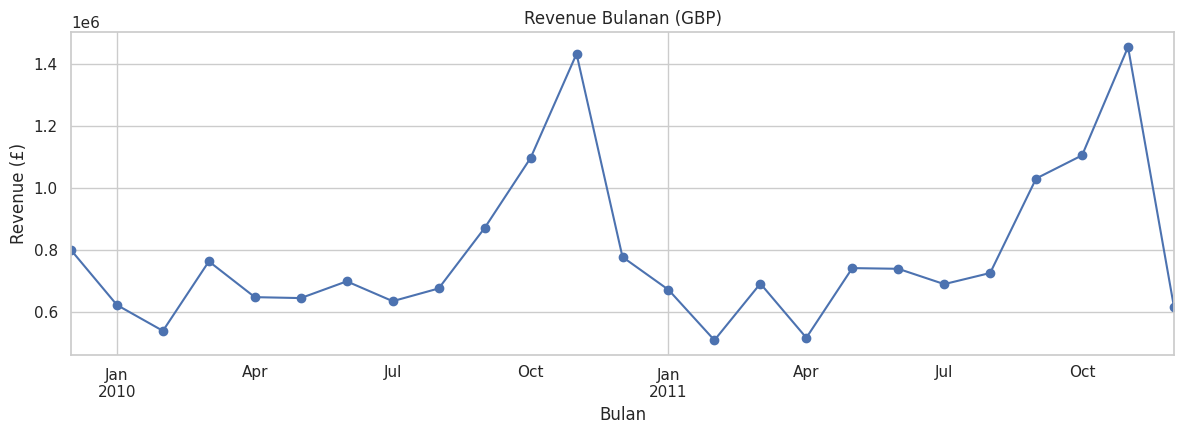

,Revenue,Orders,Customers,MoM_Growth_%
YearMonth,,,,
2009-12,"798,732.03",1671,952,NaN
2010-01,"621,503.43",1089,718,-22.19
2010-02,"538,132.65",1189,771,-13.41
2010-03,"762,148.53",1647,1051,41.63
2010-04,"646,828.06",1436,939,-15.13
2010-05,"643,835.64",1484,965,-0.46
2010-06,"697,834.87",1615,1035,8.39
2010-07,"633,839.42",1509,925,-9.17
2010-08,"674,842.89",1402,910,6.47


In [34]:
#5.1 Tren revenue bulanan

monthly = df_clean.groupby("YearMonth").agg(
    Revenue=("Revenue", "sum"),
    Orders=("Invoice", "nunique"),
    Customers=("Customer ID", "nunique"),
)
monthly["MoM_Growth_%"] = monthly["Revenue"].pct_change() * 100

fig, ax = plt.subplots(figsize=(12, 4.5))
monthly["Revenue"].plot(ax=ax, marker="o")
ax.set_title("Revenue Bulanan (GBP)")
ax.set_xlabel("Bulan"); ax.set_ylabel("Revenue (£)")
plt.tight_layout(); plt.show()
monthly

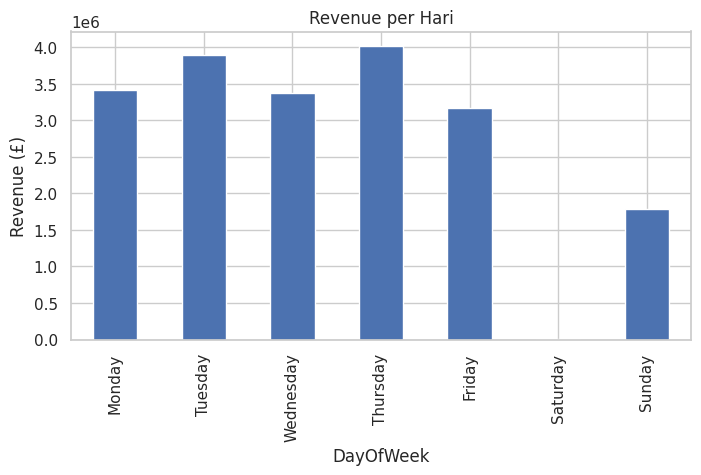

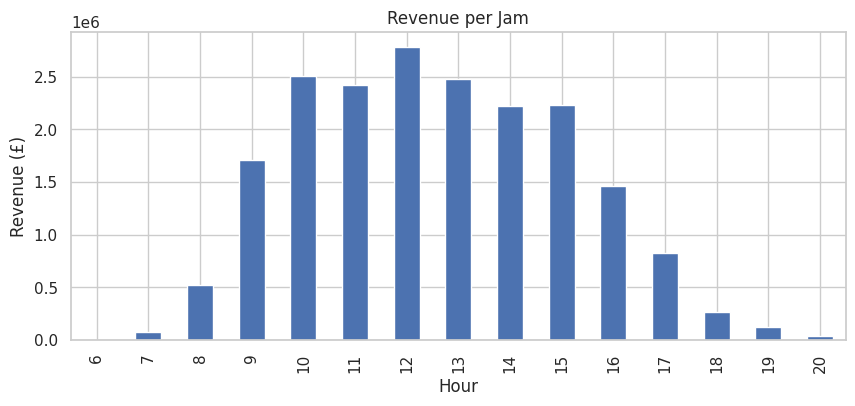

In [35]:
#5.2 Pola waktu: hari dan jam

order_hari = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
by_day = df_clean.groupby("DayOfWeek")["Revenue"].sum().reindex(order_hari)
by_day.plot(kind="bar", figsize=(8, 4), title="Revenue per Hari")
plt.ylabel("Revenue (£)"); plt.show()

by_hour = df_clean.groupby("Hour")["Revenue"].sum()
by_hour.plot(kind="bar", figsize=(10, 4), title="Revenue per Jam")
plt.ylabel("Revenue (£)"); plt.show()

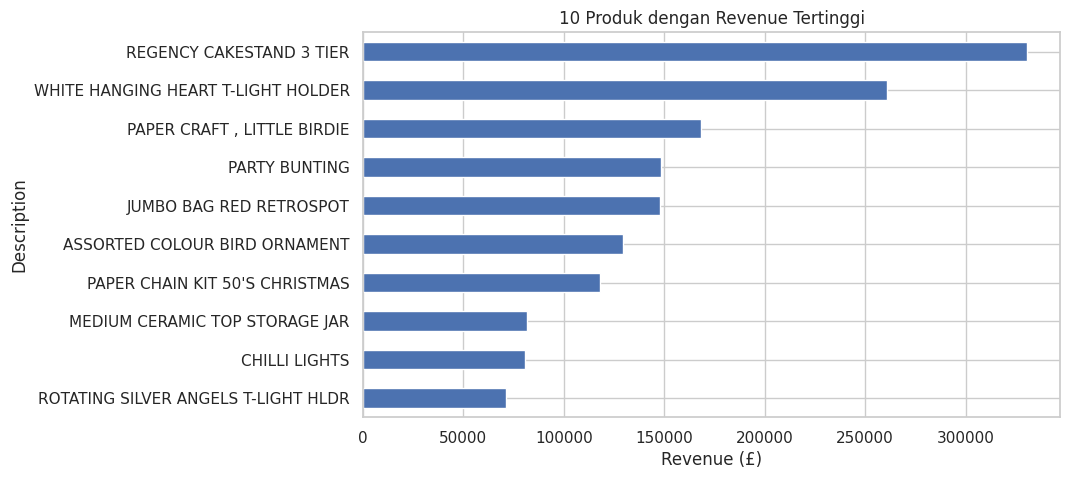

,Revenue,Qty
Description,,
REGENCY CAKESTAND 3 TIER,"330,590.32",26478
WHITE HANGING HEART T-LIGHT HOLDER,"260,990.22",94658
"PAPER CRAFT , LITTLE BIRDIE","168,469.60",80995
PARTY BUNTING,"148,318.28",28200
JUMBO BAG RED RETROSPOT,"148,073.47",77699
ASSORTED COLOUR BIRD ORNAMENT,"129,324.49",80082
PAPER CHAIN KIT 50'S CHRISTMAS,"117,760.29",35084
MEDIUM CERAMIC TOP STORAGE JAR,"81,700.92",78033
CHILLI LIGHTS,"80,540.88",15841


In [36]:
#5.3 Top produk

top_prod = (df_clean.groupby("Description")
            .agg(Revenue=("Revenue", "sum"), Qty=("Quantity", "sum"))
            .sort_values("Revenue", ascending=False).head(10))

top_prod["Revenue"].sort_values().plot(kind="barh", figsize=(9, 5),
                                       title="10 Produk dengan Revenue Tertinggi")
plt.xlabel("Revenue (£)"); plt.show()
top_prod

Country
United Kingdom   85.48
EIRE              3.23
Netherlands       2.80
Germany           1.95
France            1.58
Australia         0.85
Spain             0.50
Switzerland       0.48
Sweden            0.44
Denmark           0.34
Name: Revenue, dtype: float64


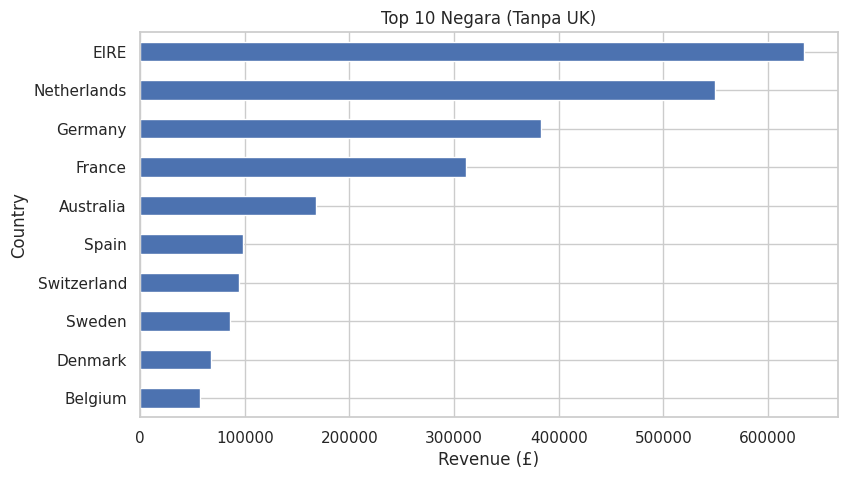

In [37]:
#5.4 Negara

by_country = df_clean.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
share = by_country / by_country.sum() * 100
print(share.head(10).round(2))

# Tanpa UK, supaya pasar internasional terlihat jelas
by_country.drop("United Kingdom").head(10).sort_values().plot(
    kind="barh", figsize=(9, 5), title="Top 10 Negara (Tanpa UK)")
plt.xlabel("Revenue (£)"); plt.show()

20% pelanggan teratas menyumbang 77.2% revenue


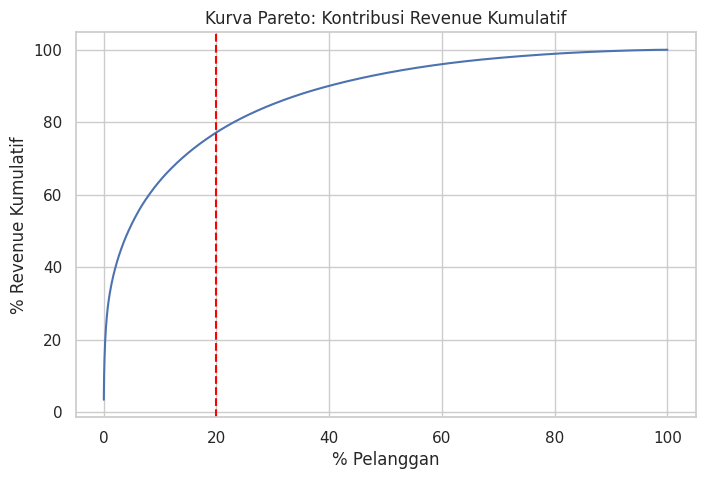

In [38]:
#5.5 Konsentrasi pelanggan (Pareto)

cust_rev = (df_clean.dropna(subset=["Customer ID"])
            .groupby("Customer ID")["Revenue"].sum()
            .sort_values(ascending=False))

cum_share = cust_rev.cumsum() / cust_rev.sum()
pct_cust = np.arange(1, len(cust_rev) + 1) / len(cust_rev)

top20 = cust_rev.head(int(len(cust_rev) * 0.2)).sum() / cust_rev.sum()
print(f"20% pelanggan teratas menyumbang {top20:.1%} revenue")

plt.figure(figsize=(8, 5))
plt.plot(pct_cust * 100, cum_share.values * 100)
plt.axvline(20, color="red", linestyle="--")
plt.title("Kurva Pareto: Kontribusi Revenue Kumulatif")
plt.xlabel("% Pelanggan"); plt.ylabel("% Revenue Kumulatif")
plt.show()

In [39]:
#5.4b Analisis pembatalan (nilai tambah)

df_cancel["Value"] = df_cancel["Quantity"] * df_cancel["Price"]
print("Jumlah invoice batal:", df_cancel["Invoice"].nunique())
print(f"Nilai pembatalan: £{df_cancel['Value'].abs().sum():,.0f}")
print(f"Rasio terhadap revenue: {df_cancel['Value'].abs().sum() / total_rev:.1%}")

Jumlah invoice batal: 8292
Nilai pembatalan: £1,462,798
Rasio terhadap revenue: 7.4%


Tahap 6: Analisis RFM

In [40]:
rfm_df = df_clean.dropna(subset=["Customer ID"])
snapshot = rfm_df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = rfm_df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
)

rfm["R"] = pd.qcut(rfm["Recency"], 4, labels=[4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"], 4, labels=[1, 2, 3, 4]).astype(int)

def segmen(row):
    R, F = row["R"], row["F"]
    if R == 4 and F == 4:        return "Champions"
    elif R >= 3 and F >= 3:      return "Loyal Customers"
    elif R == 4 and F <= 2:      return "New Customers"
    elif R <= 2 and F >= 3:      return "At Risk"
    elif R == 1 and F <= 2:      return "Lost"
    else:                        return "Need Attention"

rfm["Segment"] = rfm.apply(segmen, axis=1)

Ringkasan per segmen:

In [41]:
seg = rfm.groupby("Segment").agg(
    Pelanggan=("Monetary", "size"),
    Revenue=("Monetary", "sum"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
)
seg["%_Pelanggan"] = seg["Pelanggan"] / seg["Pelanggan"].sum() * 100
seg["%_Revenue"] = seg["Revenue"] / seg["Revenue"].sum() * 100
seg = seg.sort_values("Revenue", ascending=False)
seg

,Pelanggan,Revenue,Avg_Recency,Avg_Frequency,Avg_Monetary,%_Pelanggan,%_Revenue
Segment,,,,,,,
Champions,775,"9,482,512.79",10.72,21.99,"12,235.50",13.22,55.50
Loyal Customers,1278,"3,655,355.15",41.56,7.28,"2,860.22",21.80,21.39
At Risk,878,"2,163,798.87",278.09,6.49,"2,464.46",14.98,12.66
Need Attention,1364,"847,558.20",165.07,1.67,621.38,23.27,4.96
Lost,1227,"552,845.13",523.87,1.36,450.57,20.93,3.24
New Customers,340,"383,554.15",13.74,1.90,"1,128.10",5.80,2.24


Tahap 6b: Cohort Retention

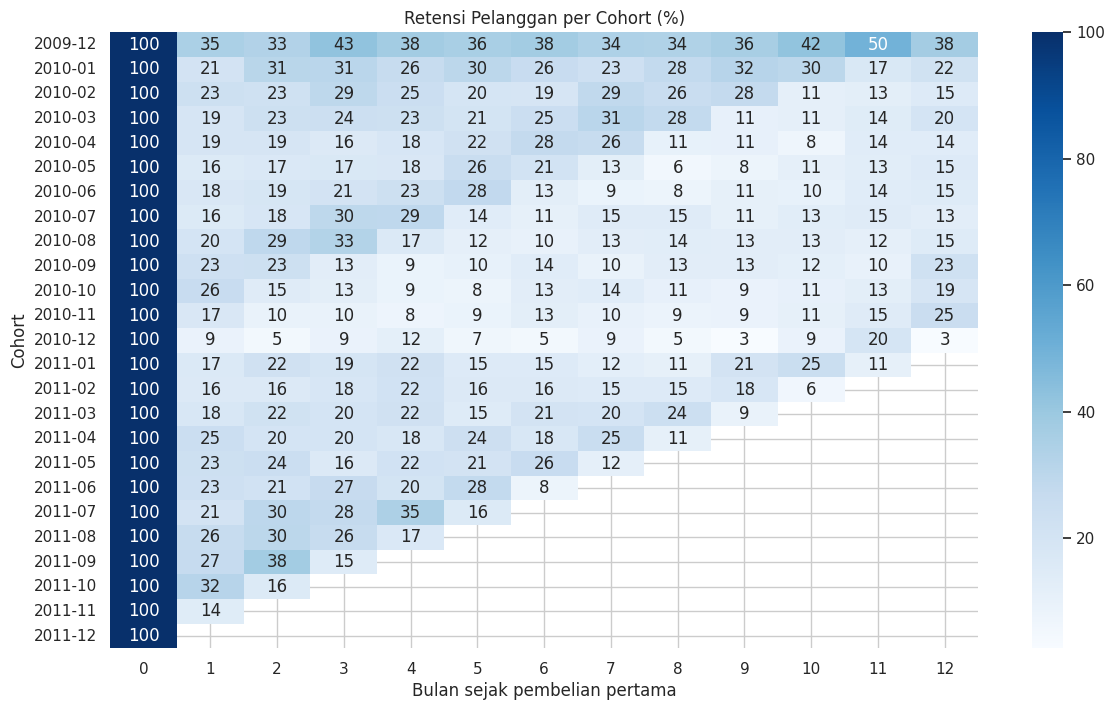

In [42]:
c = rfm_df.copy()
c["OrderMonth"] = c["InvoiceDate"].dt.to_period("M")
c["CohortMonth"] = c.groupby("Customer ID")["InvoiceDate"].transform("min").dt.to_period("M")
c["CohortIndex"] = ((c["OrderMonth"].dt.year - c["CohortMonth"].dt.year) * 12
                    + (c["OrderMonth"].dt.month - c["CohortMonth"].dt.month))

cohort = c.groupby(["CohortMonth", "CohortIndex"])["Customer ID"].nunique().unstack(1)
retention = cohort.divide(cohort[0], axis=0) * 100

plt.figure(figsize=(14, 8))
sns.heatmap(retention.iloc[:, :13], annot=True, fmt=".0f", cmap="Blues")
plt.title("Retensi Pelanggan per Cohort (%)")
plt.xlabel("Bulan sejak pembelian pertama"); plt.ylabel("Cohort")
plt.show()

Tahap 7: Insight dan Rekomendasi

In [43]:
print("""
=========================================================================
              INSIGHT DAN REKOMENDASI STRATEGIS (CRISP-DM)
=========================================================================

1. SEGMENTASI PELANGGAN VIP (KONSENTRASI REVENUE)
-------------------------------------------------------------------------
* Temuan:
  Bisnis memiliki ketergantungan yang sangat tinggi pada kelompok pelanggan bernilai tinggi (VIP).
* Bukti (Angka):
  - 20% pelanggan teratas menyumbang 77.2% dari total revenue.
  - Segmen 'Champions' (hanya 13.22% dari total pelanggan) menyumbang 55.50% total revenue (£9.48M)
    dengan rata-rata belanja fantastis sebesar £12,235.50 per pelanggan.
* Rekomendasi:
  Membuat program loyalitas eksklusif (loyalty program) berjenjang, memberikan early-access produk,
  serta menugaskan Account Manager khusus untuk mengamankan retensi kelompok VIP ini.
* Dampak:
  Mengamankan dan menstabilkan lebih dari 75% aliran pendapatan (revenue) utama perusahaan dari risiko churn.

2. REAKTIVASI PELANGGAN PASIF (AT RISK)
-------------------------------------------------------------------------
* Temuan:
  Adanya potensi revenue besar yang mengendap pada kelompok pelanggan yang sebelumnya sangat aktif namun kini mulai ditinggalkan.
* Bukti (Angka):
  - Segmen 'At Risk' mencakup 14.98% dari total pelanggan dan menyumbang 12.66% revenue (£2.16M).
  - Kelompok ini memiliki rata-rata frekuensi pembelian historis yang cukup tinggi (6.49 kali)
    namun memiliki rata-rata hari sejak pembelian terakhir (Recency) mencapai 278 hari.
* Rekomendasi:
  Meluncurkan kampanye reaktivasi otomatis berbasis email pemasaran (personalized win-back campaign)
  yang menawarkan insentif relevan (seperti diskon khusus atau penawaran produk baru berdasarkan riwayat belanja).
* Dampak:
  Mengembalikan loyalitas segmen 'At Risk' dan berpotensi memulihkan nilai penjualan hingga £2M+.

3. PENURUNAN ANGKA PEMBATALAN (REVENUE LEAKAGE)
-------------------------------------------------------------------------
* Temuan:
  Terjadi kebocoran pendapatan yang signifikan akibat tingginya transaksi yang dibatalkan (cancellation rate).
* Bukti (Angka):
  - Total nilai pembatalan mencapai £1,462,798 yang setara dengan 7.4% dari keseluruhan revenue bersih.
  - Terdapat 8,292 invoice pembatalan yang tercatat secara keseluruhan.
* Rekomendasi:
  Melakukan investigasi mendalam terhadap penyebab utama pembatalan (seperti kendala teknis sistem pembayaran,
  masalah stok barang di gudang, atau keterlambatan pengiriman) serta memperketat proses checkout.
* Dampak:
  Mengurangi kerugian/kebocoran potensi revenue dan menyelamatkan margin keuntungan hingga £1.4M.

4. OPTIMALISASI OPERASIONAL & WAKTU PEMASARAN
-------------------------------------------------------------------------
* Temuan:
  Aktivitas pembelian pelanggan sangat terpusat pada hari dan jam-jam tertentu di siang hari, serta bersifat musiman.
* Bukti (Angka):
  - Transaksi harian memuncak pada hari Kamis (£4.01M) dan Selasa (£3.89M).
  - Jam operasional tersibuk terjadi pada pukul 10:00 - 15:00 dengan puncak tertinggi pada jam 12:00 siang (£2.78M).
  - Terjadi lonjakan musiman yang sangat besar pada periode September - November.
* Rekomendasi:
  Mengirimkan buletin promosi atau flash sale terjadwal pada hari Selasa/Kamis sekitar pukul 09:00 - 11:00
  serta mengantisipasi ketersediaan stok barang terlaris sebelum memasuki kuartal 3 (Q3).
* Dampak:
  Meningkatkan conversion rate kampanye pemasaran digital dan menghindari kehabisan stok pada masa puncak (peak season).

5. RETENSI PELANGGAN BARU (COHORT DRIFT)
-------------------------------------------------------------------------
* Temuan:
  Kemampuan perusahaan dalam mempertahankan pelanggan baru setelah pembelian pertama masih tergolong rendah.
* Bukti (Angka):
  - Analisis Cohort menunjukkan retensi anjlok drastis pada bulan ke-2 (Index 1) ke kisaran rata-rata hanya 15% - 25%.
* Rekomendasi:
  Mendesain ulang program onboarding pasca-pembelian pertama (seperti email terima kasih, voucher diskon belanja kedua,
  atau survei kepuasan pelanggan secara cepat).
* Dampak:
  Meningkatkan tingkat retensi pelanggan baru pada bulan pertama sebesar 5% - 10% dan meningkatkan Customer Lifetime Value (CLV).
""")


              INSIGHT DAN REKOMENDASI STRATEGIS (CRISP-DM)

1. SEGMENTASI PELANGGAN VIP (KONSENTRASI REVENUE)
-------------------------------------------------------------------------
* Temuan:
  Bisnis memiliki ketergantungan yang sangat tinggi pada kelompok pelanggan bernilai tinggi (VIP).
* Bukti (Angka):
  - 20% pelanggan teratas menyumbang 77.2% dari total revenue.
  - Segmen 'Champions' (hanya 13.22% dari total pelanggan) menyumbang 55.50% total revenue (£9.48M)
    dengan rata-rata belanja fantastis sebesar £12,235.50 per pelanggan.
* Rekomendasi:
  Membuat program loyalitas eksklusif (loyalty program) berjenjang, memberikan early-access produk,
  serta menugaskan Account Manager khusus untuk mengamankan retensi kelompok VIP ini.
* Dampak:
  Mengamankan dan menstabilkan lebih dari 75% aliran pendapatan (revenue) utama perusahaan dari risiko churn.

2. REAKTIVASI PELANGGAN PASIF (AT RISK)
-------------------------------------------------------------------------
* Temuan:
  Adany